In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("No GPU detected. Check Runtime > Change runtime type.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [4]:
%pip -q install kaggle
print("Kaggle package installed.")

Kaggle package installed.


In [5]:

from google.colab import files
import os
import shutil

uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise ValueError(
        "Please upload the file named kaggle.json."
    )

kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)

shutil.copyfile(
    "kaggle.json",
    os.path.join(kaggle_dir, "kaggle.json")
)

os.chmod(
    os.path.join(kaggle_dir, "kaggle.json"),
    0o600
)

# Remove the temporary copy from the notebook's working directory.
os.remove("kaggle.json")

print("Kaggle credentials configured.")


Saving kaggle.json to kaggle.json
Kaggle credentials configured.


In [6]:

from pathlib import Path
import subprocess

DATA_ROOT = Path("/content/alzheimer_data")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

dataset_slug = "preetpalsingh25/alzheimers-dataset-4-class-of-images"

result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", dataset_slug,
        "-p", str(DATA_ROOT),
        "--unzip"
    ],
    capture_output=True,
    text=True
)

print(result.stdout[-4000:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError(
        "Dataset download failed. Check Kaggle credentials "
        "and dataset access."
    )

print("Download and extraction completed.")


Dataset URL: https://www.kaggle.com/datasets/preetpalsingh25/alzheimers-dataset-4-class-of-images
License(s): unknown


Download and extraction completed.


In [7]:

from pathlib import Path

for path in sorted(DATA_ROOT.rglob("*")):
    if path.is_dir():
        print(f"[DIR]  {path.relative_to(DATA_ROOT)}")
    elif path.is_file():
        print(f"[FILE] {path.relative_to(DATA_ROOT)}")


Streaming output truncated to the last 5000 lines.
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1396.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1397.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1398.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1399.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_14.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_140.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1400.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1401.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1402.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1403.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1404.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1405.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1406.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1407.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1408.jpg
[FILE] Alzheimer_s Dataset/train/NonDemented/non_1409.jpg
[FILE] Alzheimer_s Datas

In [8]:

from collections import Counter

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_counts = Counter()

for image_path in DATA_ROOT.rglob("*"):
    if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
        relative = image_path.relative_to(DATA_ROOT)
        # Group by the parent folder (normally the class name).
        image_counts[str(relative.parent)] += 1

print("Image counts by folder:")
for folder, count in sorted(image_counts.items()):
    print(f"{folder}: {count}")

print("\nTotal images:", sum(image_counts.values()))


Image counts by folder:
Alzheimer_s Dataset/test/MildDemented: 896
Alzheimer_s Dataset/test/ModerateDemented: 64
Alzheimer_s Dataset/test/NonDemented: 3200
Alzheimer_s Dataset/test/VeryMildDemented: 2240
Alzheimer_s Dataset/train/MildDemented: 896
Alzheimer_s Dataset/train/ModerateDemented: 64
Alzheimer_s Dataset/train/NonDemented: 3200
Alzheimer_s Dataset/train/VeryMildDemented: 2240

Total images: 12800


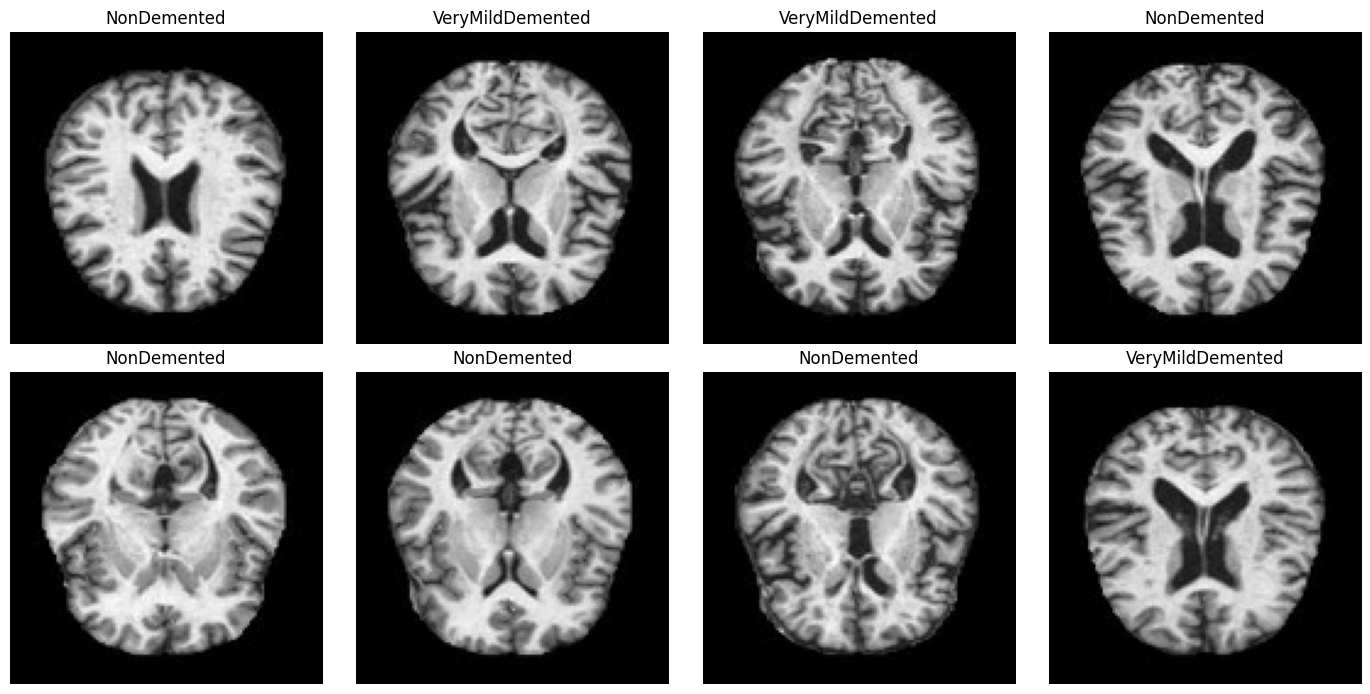

In [9]:

import random
import matplotlib.pyplot as plt
from PIL import Image

image_paths = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

if not image_paths:
    raise RuntimeError("No images found. Check the extraction path.")

sample_paths = random.Random(42).sample(
    image_paths, min(8, len(image_paths))
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, path in zip(axes, sample_paths):
    with Image.open(path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(path.parent.name)
    ax.axis("off")

for ax in axes[len(sample_paths):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:

from pathlib import Path
from collections import defaultdict
import hashlib

DATASET_ROOT = DATA_ROOT / "Alzheimer_s Dataset"
TRAIN_DIR = DATASET_ROOT / "train"
TEST_DIR = DATASET_ROOT / "test"

assert TRAIN_DIR.is_dir(), f"Missing folder: {TRAIN_DIR}"
assert TEST_DIR.is_dir(), f"Missing folder: {TEST_DIR}"

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

train_hashes = defaultdict(list)
test_hashes = defaultdict(list)

for path in TRAIN_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        train_hashes[sha256_file(path)].append(path)

for path in TEST_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        test_hashes[sha256_file(path)].append(path)

shared_hashes = set(train_hashes) & set(test_hashes)

print("Unique training image files:", len(train_hashes))
print("Unique test image files:", len(test_hashes))
print("Exact image hashes shared across splits:", len(shared_hashes))

for digest in list(shared_hashes)[:10]:
    print("\nMatching files:")
    print("Train:", train_hashes[digest][0])
    print("Test: ", test_hashes[digest][0])


Unique training image files: 6400
Unique test image files: 6400
Exact image hashes shared across splits: 6400

Matching files:
Train: /content/alzheimer_data/Alzheimer_s Dataset/train/VeryMildDemented/verymild_1074.jpg
Test:  /content/alzheimer_data/Alzheimer_s Dataset/test/VeryMildDemented/verymild_1074.jpg

Matching files:
Train: /content/alzheimer_data/Alzheimer_s Dataset/train/VeryMildDemented/verymild_32.jpg
Test:  /content/alzheimer_data/Alzheimer_s Dataset/test/VeryMildDemented/verymild_32.jpg

Matching files:
Train: /content/alzheimer_data/Alzheimer_s Dataset/train/NonDemented/non_1598.jpg
Test:  /content/alzheimer_data/Alzheimer_s Dataset/test/NonDemented/non_1598.jpg

Matching files:
Train: /content/alzheimer_data/Alzheimer_s Dataset/train/NonDemented/non_2723.jpg
Test:  /content/alzheimer_data/Alzheimer_s Dataset/test/NonDemented/non_2723.jpg

Matching files:
Train: /content/alzheimer_data/Alzheimer_s Dataset/train/VeryMildDemented/verymild_1980.jpg
Test:  /content/alzheimer

In [11]:

import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
from torchvision import datasets

SEED = 42

# Use only one copy of the duplicated dataset.
source_dataset = datasets.ImageFolder(str(TRAIN_DIR))

class_names = source_dataset.classes
labels = np.array(source_dataset.targets)
indices = np.arange(len(source_dataset))

# 70% train, 30% temporary holdout.
train_idx, holdout_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels,
)

# Split holdout equally into validation and internal test.
val_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[holdout_idx],
)

print("Classes:", class_names)
print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Internal test images:", len(test_idx))

for name, split_idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Internal test", test_idx),
]:
    print(f"\n{name} class distribution:")
    print(Counter(class_names[labels[i]] for i in split_idx))

# Verify that no image index is shared between subsets.
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

print("\nSplit verification passed.")


Classes: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
Training images: 4480
Validation images: 960
Internal test images: 960

Train class distribution:
Counter({'NonDemented': 2240, 'VeryMildDemented': 1568, 'MildDemented': 627, 'ModerateDemented': 45})

Validation class distribution:
Counter({'NonDemented': 480, 'VeryMildDemented': 336, 'MildDemented': 134, 'ModerateDemented': 10})

Internal test class distribution:
Counter({'NonDemented': 480, 'VeryMildDemented': 336, 'MildDemented': 135, 'ModerateDemented': 9})

Split verification passed.


In [12]:

import torch
import numpy as np
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ImageNet normalization for pretrained ResNet50.
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    normalize,
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    normalize,
])

# Keep the same image ordering so our split indices remain valid.
train_source = datasets.ImageFolder(
    str(TRAIN_DIR), transform=train_transform
)
eval_source = datasets.ImageFolder(
    str(TRAIN_DIR), transform=eval_transform
)

assert train_source.classes == class_names
assert eval_source.classes == class_names

train_loader = DataLoader(
    Subset(train_source, train_idx.tolist()),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    Subset(eval_source, val_idx.tolist()),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    Subset(eval_source, test_idx.tolist()),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

images, targets = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", targets.shape)
print("Class names:", class_names)


Using device: cuda
Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Class names: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']


In [13]:

from torchvision import models
from torchvision.models import ResNet50_Weights
from pathlib import Path

MODEL_DIR = Path("/content/alzheimer_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

weights = ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Freeze pretrained feature extraction layers.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the final layer for our four classes.
model.fc = nn.Linear(
    model.fc.in_features,
    len(class_names),
)

model = model.to(device)

# Inverse-frequency weights computed from the training subset.
train_counts = np.bincount(
    labels[train_idx],
    minlength=len(class_names),
)

class_weights = len(train_idx) / (
    len(class_names) * train_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device,
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

print("Model:", type(model).__name__)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))
print("Class weights:", {
    name: round(float(weight), 3)
    for name, weight in zip(class_names, class_weights.cpu())
})


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 169MB/s]


Model: ResNet
Trainable parameters: 8196
Class weights: {'MildDemented': 1.786, 'ModerateDemented': 24.889, 'NonDemented': 0.5, 'VeryMildDemented': 0.714}


In [14]:

from google.colab import drive

drive.mount("/content/drive")

DRIVE_MODEL_DIR = Path(
    "/content/drive/MyDrive/alzheimer_project/models"
)
DRIVE_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Persistent model directory:", DRIVE_MODEL_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent model directory: /content/drive/MyDrive/alzheimer_project/models


In [15]:

import copy
import json
from tqdm.auto import tqdm

EPOCHS = 10
best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
history = []

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for x, y in tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}",
        leave=False,
    ):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * y.size(0)
        train_correct += (logits.argmax(1) == y).sum().item()
        train_total += y.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            val_loss_sum += loss.item() * y.size(0)
            val_correct += (logits.argmax(1) == y).sum().item()
            val_total += y.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
    }
    history.append(row)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f} | "
        f"train acc {train_acc:.4f} | "
        f"val loss {val_loss:.4f} | "
        f"val acc {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": best_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "class_names": class_names,
            "image_size": IMAGE_SIZE,
            "architecture": "resnet50",
            "best_val_loss": best_val_loss,
        }

        torch.save(
            checkpoint,
            DRIVE_MODEL_DIR / "resnet50_best.pth",
        )

        torch.save(
            checkpoint,
            MODEL_DIR / "resnet50_best.pth",
        )

        print("  Saved best checkpoint.")

# Restore the best validation checkpoint.
model.load_state_dict(best_state)

with open(DRIVE_MODEL_DIR / "history.json", "w") as f:
    json.dump(history, f, indent=2)

print("\nTraining finished.")
print("Best validation loss:", round(best_val_loss, 4))
print("Saved to:", DRIVE_MODEL_DIR)


Epoch 1/10:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 01/10 | train loss 1.3005 | train acc 0.4440 | val loss 1.2143 | val acc 0.5115
  Saved best checkpoint.


Epoch 2/10:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 02/10 | train loss 1.1883 | train acc 0.5375 | val loss 1.1215 | val acc 0.5698
  Saved best checkpoint.


Epoch 3/10:   0%|          | 0/140 [00:00<?, ?it/s]

...

Epoch 9/10:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 09/10 | train loss 0.9862 | train acc 0.5643 | val loss 0.9521 | val acc 0.5542


Epoch 10/10:   0%|          | 0/140 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a9b96bc4ea0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a9b96bc4ea0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 10/10 | train loss 0.9361 | train acc 0.5676 | val loss 0.9409 | val acc 0.5927
  Saved best checkpoint.

Training finished.
Best validation loss: 0.9409
Saved to: /content/drive/MyDrive/alzheimer_project/models


Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Internal test accuracy: 0.5687
Macro F1: 0.5086

Classification report:
                  precision    recall  f1-score   support

    MildDemented       0.36      0.63      0.45       135
ModerateDemented       0.50      0.33      0.40         9
     NonDemented       0.76      0.59      0.66       480
VeryMildDemented       0.51      0.52      0.52       336

        accuracy                           0.57       960
       macro avg       0.53      0.52      0.51       960
    weighted avg       0.61      0.57      0.58       960



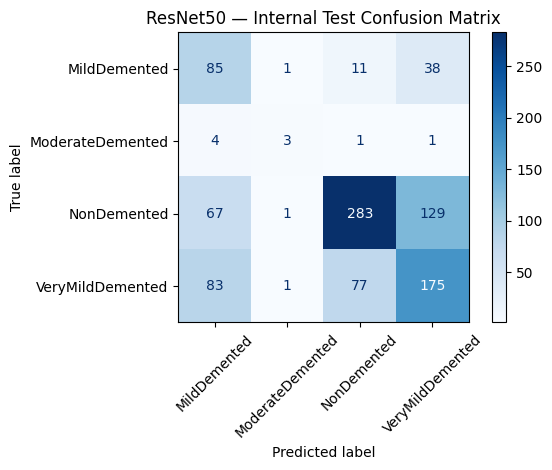

In [16]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for x, y in tqdm(test_loader, desc="Evaluating"):
        logits = model(x.to(device))
        predictions = logits.argmax(dim=1).cpu().numpy()

        y_true.extend(y.numpy().tolist())
        y_pred.extend(predictions.tolist())

print("Internal test accuracy:", round(
    accuracy_score(y_true, y_pred), 4
))
print("Macro F1:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues",
)
plt.title("ResNet50 — Internal Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [17]:
from torch.utils.data import DataLoader, Subset

BATCH_SIZE = 32
NUM_WORKERS = 0

train_loader = DataLoader(
    Subset(train_source, train_idx.tolist()),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    Subset(eval_source, val_idx.tolist()),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    Subset(eval_source, test_idx.tolist()),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print("DataLoaders recreated with NUM_WORKERS=0")

DataLoaders recreated with NUM_WORKERS=0


In [18]:
import copy
import json
import torch
from torch import nn

# Freeze all layers first
for parameter in model.parameters():
    parameter.requires_grad = False

# Fine-tune the final residual block and classifier
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

for parameter in model.fc.parameters():
    parameter.requires_grad = True

# Softer class weighting to reduce overcorrection
train_counts = np.bincount(
    labels[train_idx],
    minlength=len(class_names)
)

class_weights_ft = np.sqrt(
    train_counts.sum() / (len(class_names) * train_counts)
)
class_weights_ft = class_weights_ft / class_weights_ft.mean()

criterion_ft = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights_ft,
        dtype=torch.float32,
        device=device
    )
)

optimizer_ft = torch.optim.AdamW(
    [
        {"params": model.layer4.parameters(), "lr": 1e-4},
        {"params": model.fc.parameters(), "lr": 3e-4},
    ],
    weight_decay=1e-4,
)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Fine-tuning class weights:", class_weights_ft.round(3))

Trainable parameters: 14972932
Fine-tuning class weights: [0.679 2.533 0.359 0.429]


In [19]:
import copy
import json
from tqdm.auto import tqdm

EPOCHS_FT = 8
best_val_loss_ft = float("inf")
best_state_ft = copy.deepcopy(model.state_dict())
history_ft = []

for epoch in range(EPOCHS_FT):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for x, y in tqdm(
        train_loader,
        desc=f"Fine-tuning {epoch + 1}/{EPOCHS_FT}",
        leave=False
    ):
        x = x.to(device)
        y = y.to(device)

        optimizer_ft.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion_ft(logits, y)
        loss.backward()
        optimizer_ft.step()

        train_loss_sum += loss.item() * y.size(0)
        train_correct += (logits.argmax(1) == y).sum().item()
        train_total += y.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss_sum = 0.0
    val_total = 0

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            loss = criterion_ft(logits, y)

            val_loss_sum += loss.item() * y.size(0)
            val_total += y.size(0)

    val_loss = val_loss_sum / val_total

    history_ft.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS_FT} | "
        f"train loss {train_loss:.4f} | "
        f"train acc {train_acc:.4f} | "
        f"val loss {val_loss:.4f}"
    )

    if val_loss < best_val_loss_ft:
        best_val_loss_ft = val_loss
        best_state_ft = copy.deepcopy(model.state_dict())

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": best_state_ft,
            "class_names": class_names,
            "image_size": IMAGE_SIZE,
            "architecture": "resnet50",
            "best_val_loss": best_val_loss_ft,
        }

        torch.save(
            checkpoint,
            DRIVE_MODEL_DIR / "resnet50_finetuned_best.pth"
        )
        print("  Saved best fine-tuned checkpoint.")

model.load_state_dict(best_state_ft)

with open(DRIVE_MODEL_DIR / "history_finetuned.json", "w") as f:
    json.dump(history_ft, f, indent=2)

print("Fine-tuning complete.")
print("Best fine-tuning validation loss:", round(best_val_loss_ft, 4))

Fine-tuning 1/8:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 01/8 | train loss 0.8411 | train acc 0.6357 | val loss 0.7255
  Saved best fine-tuned checkpoint.


Fine-tuning 2/8:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 02/8 | train loss 0.6792 | train acc 0.7000 | val loss 0.6299
  Saved best fine-tuned checkpoint.


Fine-tuning 3/8:   0%|          | 0/140 [00:00<?, ?it/s]

...

Epoch 06/8 | train loss 0.2732 | train acc 0.8940 | val loss 0.3731
  Saved best fine-tuned checkpoint.


Fine-tuning 7/8:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 07/8 | train loss 0.2264 | train acc 0.9083 | val loss 0.4478


Fine-tuning 8/8:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 08/8 | train loss 0.2055 | train acc 0.9199 | val loss 0.3763
Fine-tuning complete.
Best fine-tuning validation loss: 0.3731


Fine-tuned test evaluation:   0%|          | 0/30 [00:00<?, ?it/s]

Internal test accuracy: 0.8385 (83.85%)
Macro F1-score:         0.8392
Balanced accuracy:      0.8260

Classification report:
                  precision    recall  f1-score   support

    MildDemented       0.75      0.88      0.81       135
ModerateDemented       1.00      0.78      0.88         9
     NonDemented       0.88      0.88      0.88       480
VeryMildDemented       0.82      0.77      0.79       336

        accuracy                           0.84       960
       macro avg       0.86      0.83      0.84       960
    weighted avg       0.84      0.84      0.84       960



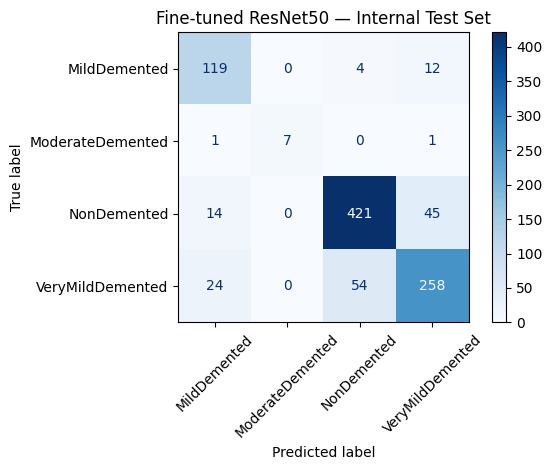

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# model already contains the best fine-tuned weights
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for x, y in tqdm(test_loader, desc="Fine-tuned test evaluation"):
        x = x.to(device, non_blocking=True)
        logits = model(x)
        predictions = logits.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions.tolist())
        y_true.extend(y.numpy().tolist())

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)
balanced_acc = balanced_accuracy_score(y_true, y_pred)

print(f"Internal test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro F1-score:         {macro_f1:.4f}")
print(f"Balanced accuracy:      {balanced_acc:.4f}")
print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
)
plt.title("Fine-tuned ResNet50 — Internal Test Set")
plt.tight_layout()
plt.show()

In [21]:
import json
from pathlib import Path
from sklearn.metrics import classification_report

results_dir = Path("/content/drive/MyDrive/alzheimer_project/results")
results_dir.mkdir(parents=True, exist_ok=True)

results = {
    "model": "ResNet50 fine-tuned",
    "dataset": "Alzheimer's Dataset — custom stratified image-level split",
    "test_images": len(y_true),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "balanced_accuracy": float(balanced_acc),
    "class_names": class_names,
    "classification_report": classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    ),
    "limitations": [
        "Image-level rather than patient-level split",
        "Only nine ModerateDemented images in the test set",
        "No independent clinical validation",
    ],
}

with open(results_dir / "resnet50_finetuned_test_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Evaluation results saved to:", results_dir)
print("Best model checkpoint:",
      DRIVE_MODEL_DIR / "resnet50_finetuned_best.pth")

Evaluation results saved to: /content/drive/MyDrive/alzheimer_project/results
Best model checkpoint: /content/drive/MyDrive/alzheimer_project/models/resnet50_finetuned_best.pth


In [22]:

from pathlib import Path

# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Inspect likely project locations
roots = [
    Path("/content/drive/MyDrive"),
    Path("/content")
]

for root in roots:
    print(f"\n--- Inspecting {root} ---")
    if not root.exists():
        continue

    for path in root.iterdir():
        print(path.name, "/" if path.is_dir() else "")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- Inspecting /content/drive/MyDrive ---
10th Marksheet.pdf 
12th Marksheet (1).pdf 
12th Marksheet.pdf 
Super super secret videos /
TCS /
Aashray_Jain_Resume_v5_Bond_Paper (1).pdf 
Aashray_Jain_Resume_v5_Bond_Paper.pdf 
Aashray_Jain_Resume_v5_Bond_Paper_1753085047755_Aashray Jain.PDF 
AI Ad Gen Challenge.gdoc 
Resume /
20250905_123738.pdf 
Your big idea.gslides 
Forge the Future.gslides 
Forge the Future.gdoc 
ChatGPT Image Sep 7, 2025, 01_14_51 PM.png 
Forge the Future - Hack with Future.gdoc 
NeuroSuit – Hack-to-the-Future.gslides 
ChatGPT Image Sep 7, 2025, 01_19_35 PM.pdf 
Hackathons /
MariaDB Hackathon.gdoc 
Certificates /
Artificial Intelligence Track.gsheet 
To-do list.gsheet 
Important dates of family members /
download_1771919077425.mp4 
download_1771918658837.mp4 
download_1771928253403.mp4 
download_1772093207541.mp4 
download_1772093491117.mp4 

In [23]:

from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image, UnidentifiedImageError
import hashlib
import pandas as pd

# Audit only one copy of the duplicated source dataset.
AUDIT_ROOT = TRAIN_DIR

records = []
hash_to_paths = defaultdict(list)
corrupt_files = []

for class_dir in sorted(p for p in AUDIT_ROOT.iterdir() if p.is_dir()):
    for path in sorted(class_dir.iterdir()):
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            digest = hashlib.sha256(path.read_bytes()).hexdigest()

            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                width, height = img.size
                image_format = img.format

            records.append({
                "file": str(path),
                "class": class_dir.name,
                "sha256": digest,
                "width": width,
                "height": height,
                "format": image_format,
            })
            hash_to_paths[digest].append(str(path))

        except (OSError, ValueError, UnidentifiedImageError) as exc:
            corrupt_files.append({
                "file": str(path),
                "error": str(exc)
            })

audit_df = pd.DataFrame(records)

print("DATASET AUDIT SUMMARY")
print("=" * 50)
print("Valid images:", len(audit_df))
print("Unreadable/corrupt images:", len(corrupt_files))
print("Unique SHA-256 hashes:", audit_df["sha256"].nunique())

print("\nClass distribution:")
print(audit_df["class"].value_counts().sort_index())

print("\nImage dimensions:")
print(audit_df.groupby(["width", "height"]).size()
      .sort_values(ascending=False).head(15))

duplicate_groups = {
    digest: paths
    for digest, paths in hash_to_paths.items()
    if len(paths) > 1
}

print("\nExact-duplicate groups within this source:",
      len(duplicate_groups))

if corrupt_files:
    print("\nFirst corrupt files:")
    print(pd.DataFrame(corrupt_files).head(10).to_string(index=False))

# Save the audit report to Google Drive.
from pathlib import Path

REPORT_DIR = Path("/content/drive/MyDrive/alzheimer_project/results")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(REPORT_DIR / "dataset_audit.csv", index=False)

with open(REPORT_DIR / "dataset_audit_summary.txt", "w") as f:
    f.write(f"Valid images: {len(audit_df)}\n")
    f.write(f"Corrupt images: {len(corrupt_files)}\n")
    f.write(f"Unique hashes: {audit_df['sha256'].nunique()}\n")
    f.write(f"Exact duplicate groups: {len(duplicate_groups)}\n")
    f.write("\nClass distribution:\n")
    f.write(audit_df["class"].value_counts().sort_index().to_string())

print("\nAudit report saved to:", REPORT_DIR)


DATASET AUDIT SUMMARY
Valid images: 6400
Unreadable/corrupt images: 0
Unique SHA-256 hashes: 6400

Class distribution:
class
MildDemented         896
ModerateDemented      64
NonDemented         3200
VeryMildDemented    2240
Name: count, dtype: int64

Image dimensions:
width  height
128    128       6400
dtype: int64

Exact-duplicate groups within this source: 0

Audit report saved to: /content/drive/MyDrive/alzheimer_project/results


In [24]:

import json
import pandas as pd
from pathlib import Path

# Reuse the existing stratified split from the notebook.
# Do not regenerate the split separately for each model.

split_indices = {
    "train": train_idx,
    "validation": val_idx,
    "test": test_idx,
}

rows = []

for split_name, indices in split_indices.items():
    for idx in indices:
        filepath, label = source_dataset.samples[int(idx)]

        rows.append({
            "filepath": str(filepath),
            "class_index": int(label),
            "class_name": class_names[int(label)],
            "split": split_name,
        })

manifest = pd.DataFrame(rows)

# Integrity checks
assert len(manifest) == 6400
assert manifest["filepath"].nunique() == 6400
assert manifest.groupby("split").size().to_dict() == {
    "train": 4480,
    "validation": 960,
    "test": 960,
}

output_dir = Path(
    "/content/drive/MyDrive/alzheimer_project/results"
)
output_dir.mkdir(parents=True, exist_ok=True)

manifest_path = output_dir / "split_manifest_seed42.csv"
manifest.to_csv(manifest_path, index=False)

config = {
    "dataset_images": 6400,
    "source_folder": str(TRAIN_DIR),
    "random_seed": 42,
    "split_ratios": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15,
    },
    "class_names": list(class_names),
    "split_manifest": str(manifest_path),
    "test_status": (
        "Pilot baseline test metrics previously inspected; "
        "do not use for hyperparameter tuning."
    ),
}

with open(output_dir / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Experiment split saved successfully.")
print("\nImages per split and class:")
print(pd.crosstab(manifest["split"], manifest["class_name"]))
print("\nManifest:", manifest_path)
print("Configuration:", output_dir / "experiment_config.json")


Experiment split saved successfully.

Images per split and class:
class_name  MildDemented  ModerateDemented  NonDemented  VeryMildDemented
split                                                                    
test                 135                 9          480               336
train                627                45         2240              1568
validation           134                10          480               336

Manifest: /content/drive/MyDrive/alzheimer_project/results/split_manifest_seed42.csv
Configuration: /content/drive/MyDrive/alzheimer_project/results/experiment_config.json


In [25]:

# Research Experiment v1 — reproducible model setup

import os
import json
import random
import numpy as np
import torch

from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision import models, datasets, transforms

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = Path("/content/drive/MyDrive/alzheimer_project")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Verify the saved split before training.
manifest_path = RESULTS_DIR / "split_manifest_seed42.csv"
assert manifest_path.exists(), "Split manifest not found."

import pandas as pd

manifest = pd.read_csv(manifest_path)
assert len(manifest) == 6400
assert manifest["filepath"].nunique() == 6400
assert manifest.groupby("split").size().to_dict() == {
    "train": 4480,
    "validation": 960,
    "test": 960,
}

# Recreate datasets with identical preprocessing.
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    normalize,
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    normalize,
])

train_source = datasets.ImageFolder(
    str(TRAIN_DIR), transform=train_transform
)
eval_source = datasets.ImageFolder(
    str(TRAIN_DIR), transform=eval_transform
)

class_names = train_source.classes
assert eval_source.classes == class_names

# Reconstruct indices directly from the saved manifest.
path_to_index = {
    str(path): idx
    for idx, (path, label) in enumerate(train_source.samples)
}

for _, row in manifest.iterrows():
    assert row["filepath"] in path_to_index, (
        f"Manifest path not found: {row['filepath']}"
    )
    idx = path_to_index[row["filepath"]]
    assert train_source.samples[idx][1] == int(row["class_index"])

split_indices = {
    split: [
        path_to_index[p]
        for p in manifest.loc[
            manifest["split"] == split, "filepath"
        ].tolist()
    ]
    for split in ["train", "validation", "test"]
}

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    Subset(train_source, split_indices["train"]),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    generator=generator,
)

val_loader = DataLoader(
    Subset(eval_source, split_indices["validation"]),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    Subset(eval_source, split_indices["test"]),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

# Use the same softened class weights for every architecture.
train_labels = np.array([
    train_source.samples[i][1]
    for i in split_indices["train"]
])

train_counts = np.bincount(
    train_labels, minlength=len(class_names)
)

class_weights = np.sqrt(
    len(train_labels) / (len(class_names) * train_counts)
)
class_weights /= class_weights.mean()

experiment_config = {
    "seed": SEED,
    "dataset_size": len(manifest),
    "class_names": class_names,
    "train_counts": train_counts.tolist(),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "loss": "weighted cross-entropy with normalized square-root inverse-frequency weights",
    "selection": "lowest validation loss",
    "test_policy": "reserved for final evaluation; not used for tuning",
    "architectures": ["ResNet50", "EfficientNet-B0", "DenseNet121"],
}

with open(RESULTS_DIR / "controlled_experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Classes:", class_names)
print("Training counts:", dict(zip(class_names, train_counts.tolist())))
print("Class weights:", np.round(class_weights, 3).tolist())
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Saved experiment configuration.")
print("Split manifest verified successfully.")


Device: cuda
GPU: Tesla T4
Classes: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
Training counts: {'MildDemented': 627, 'ModerateDemented': 45, 'NonDemented': 2240, 'VeryMildDemented': 1568}
Class weights: [0.679, 2.533, 0.359, 0.429]
Training batches: 140
Validation batches: 30
Test batches: 30
Saved experiment configuration.
Split manifest verified successfully.


In [26]:

# ============================================================
# Alzheimer MRI Research Experiment v1
# ResNet50 vs EfficientNet-B0 vs DenseNet121
# ============================================================

import time
import copy
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from torchvision import models

SEED = 42
HEAD_EPOCHS = 2
FINETUNE_EPOCHS = 8
PATIENCE = 3
LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_BACKBONE = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

MODEL_DIR = Path("/content/drive/MyDrive/alzheimer_project/models")
RESULTS_DIR = Path("/content/drive/MyDrive/alzheimer_project/results")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

num_classes = len(class_names)
weights_tensor = torch.tensor(
    class_weights, dtype=torch.float32, device=device
)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

# Model construction uses official ImageNet-pretrained weights.
def build_model(name):
    if name == "ResNet50":
        model = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)

    elif name == "EfficientNet-B0":
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)

    elif name == "DenseNet121":
        model = models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT
        )
        in_features = model.classifier.in_features
        model.classifier = nn.Linear(in_features, num_classes)

    else:
        raise ValueError(name)

    return model.to(device)


def freeze_backbone(model, name):
    for param in model.parameters():
        param.requires_grad = False

    # Keep only the classifier trainable during Stage A.
    if name == "ResNet50":
        for param in model.fc.parameters():
            param.requires_grad = True

    elif name == "EfficientNet-B0":
        for param in model.classifier.parameters():
            param.requires_grad = True

    elif name == "DenseNet121":
        for param in model.classifier.parameters():
            param.requires_grad = True


def unfreeze_final_stage(model, name):
    # Stage B: classifier plus the final feature stage.
    if name == "ResNet50":
        for param in model.layer4.parameters():
            param.requires_grad = True

    elif name == "EfficientNet-B0":
        for param in model.features[-2:].parameters():
            param.requires_grad = True

    elif name == "DenseNet121":
        for param in model.features.denseblock4.parameters():
            param.requires_grad = True
        for param in model.features.norm5.parameters():
            param.requires_grad = True


def run_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_samples = 0
    all_targets = []
    all_preds = []

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.amp.autocast(
                device_type="cuda",
                enabled=(device.type == "cuda")
            ):
                logits = model(images)
                loss = criterion(logits, targets)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_targets.extend(targets.detach().cpu().numpy())
        all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy())

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_targets, all_preds),
        "macro_f1": f1_score(
            all_targets, all_preds,
            average="macro", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            all_targets, all_preds
        ),
    }


def fit_model(name):
    print(f"\n{'=' * 65}\nTraining {name}\n{'=' * 65}")

    model = build_model(name)
    checkpoint_path = MODEL_DIR / (
        name.lower().replace("-", "_") + "_best.pth"
    )

    scaler = torch.amp.GradScaler(
        "cuda", enabled=(device.type == "cuda")
    )

    history = []
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    stale_epochs = 0
    start_time = time.time()

    # Stage A: classifier head
    freeze_backbone(model, name)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATE_HEAD,
        weight_decay=1e-4,
    )

    for epoch in range(1, HEAD_EPOCHS + 1):
        train_metrics = run_epoch(
            model, train_loader, optimizer, scaler
        )
        val_metrics = run_epoch(model, val_loader)

        row = {
            "model": name, "stage": "head",
            "epoch": epoch,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()},
        }
        history.append(row)

        print(
            f"Head {epoch}/{HEAD_EPOCHS} | "
            f"train loss={train_metrics['loss']:.4f} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val macro-F1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = len(history)
            stale_epochs = 0
        else:
            stale_epochs += 1

    # Stage B: fine-tune final feature layers
    unfreeze_final_stage(model, name)

    optimizer = torch.optim.AdamW(
        [
            {
                "params": [
                    p for p in model.parameters()
                    if p.requires_grad
                ],
                "lr": LEARNING_RATE_BACKBONE,
            }
        ],
        weight_decay=1e-4,
    )

    for epoch in range(1, FINETUNE_EPOCHS + 1):
        train_metrics = run_epoch(
            model, train_loader, optimizer, scaler
        )
        val_metrics = run_epoch(model, val_loader)

        row = {
            "model": name, "stage": "finetune",
            "epoch": epoch,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()},
        }
        history.append(row)

        print(
            f"Fine-tune {epoch}/{FINETUNE_EPOCHS} | "
            f"train loss={train_metrics['loss']:.4f} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val macro-F1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = len(history)
            stale_epochs = 0
        else:
            stale_epochs += 1

        if stale_epochs >= PATIENCE:
            print("Early stopping: validation loss did not improve.")
            break

    if best_state is None:
        raise RuntimeError(f"No checkpoint produced for {name}")

    model.load_state_dict(best_state)

    torch.save(
        {
            "model_name": name,
            "state_dict": best_state,
            "class_names": class_names,
            "best_validation_loss": best_val_loss,
            "best_epoch_in_history": best_epoch,
            "seed": SEED,
        },
        checkpoint_path,
    )

    elapsed = time.time() - start_time

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        RESULTS_DIR /
        (name.lower().replace("-", "_") + "_history.csv"),
        index=False,
    )

    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Best epoch in history: {best_epoch}")
    print(f"Training time: {elapsed / 60:.1f} minutes")
    print(f"Checkpoint: {checkpoint_path}")

    del model, optimizer, scaler, best_state
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "model": name,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "training_minutes": elapsed / 60,
        "checkpoint": str(checkpoint_path),
    }, history_df


# Sequential training helps manage GPU memory.
training_summaries = []
all_histories = []

for model_name in ["ResNet50", "EfficientNet-B0", "DenseNet121"]:
    summary, history_df = fit_model(model_name)
    training_summaries.append(summary)
    all_histories.append(history_df)

summary_df = pd.DataFrame(training_summaries)
summary_df.to_csv(
    RESULTS_DIR / "model_training_summary.csv", index=False
)

history_df = pd.concat(all_histories, ignore_index=True)
history_df.to_csv(
    RESULTS_DIR / "all_models_training_history.csv", index=False
)

print("\nTRAINING COMPLETE")
print(summary_df.to_string(index=False))
print("\nResults saved in:", RESULTS_DIR)



Training ResNet50
Head 1/2 | train loss=1.1673 | val loss=1.0887 | val macro-F1=0.3048
Head 2/2 | train loss=1.0636 | val loss=1.0418 | val macro-F1=0.3338
Fine-tune 1/8 | train loss=0.9495 | val loss=0.8018 | val macro-F1=0.6542
Fine-tune 2/8 | train loss=0.7415 | val loss=0.6374 | val macro-F1=0.7040
Fine-tune 3/8 | train loss=0.5727 | val loss=0.5289 | val macro-F1=0.7967
Fine-tune 4/8 | train loss=0.4457 | val loss=0.6235 | val macro-F1=0.7165
Fine-tune 5/8 | train loss=0.3503 | val loss=0.4368 | val macro-F1=0.8260
Fine-tune 6/8 | train loss=0.2688 | val loss=0.4399 | val macro-F1=0.8444
Fine-tune 7/8 | train loss=0.2431 | val loss=0.3273 | val macro-F1=0.8812
Fine-tune 8/8 | train loss=0.1966 | val loss=0.3463 | val macro-F1=0.8680
Best validation loss: 0.3273
Best epoch in history: 9
Training time: 3.2 minutes
Checkpoint: /content/drive/MyDrive/alzheimer_project/models/resnet50_best.pth

Training EfficientNet-B0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_

100%|██████████| 20.5M/20.5M [00:00<00:00, 148MB/s]


Head 1/2 | train loss=1.1173 | val loss=1.0339 | val macro-F1=0.3935
Head 2/2 | train loss=1.0094 | val loss=0.9682 | val macro-F1=0.4053
Fine-tune 1/8 | train loss=0.9739 | val loss=0.8963 | val macro-F1=0.5083
Fine-tune 2/8 | train loss=0.9216 | val loss=0.8512 | val macro-F1=0.5785
Fine-tune 3/8 | train loss=0.8677 | val loss=0.8151 | val macro-F1=0.6371
Fine-tune 4/8 | train loss=0.8415 | val loss=0.7846 | val macro-F1=0.6636
Fine-tune 5/8 | train loss=0.7856 | val loss=0.7282 | val macro-F1=0.6992
Fine-tune 6/8 | train loss=0.7614 | val loss=0.7254 | val macro-F1=0.6827
Fine-tune 7/8 | train loss=0.7375 | val loss=0.6820 | val macro-F1=0.7081
Fine-tune 8/8 | train loss=0.7104 | val loss=0.6841 | val macro-F1=0.6889
Best validation loss: 0.6820
Best epoch in history: 9
Training time: 3.2 minutes
Checkpoint: /content/drive/MyDrive/alzheimer_project/models/efficientnet_b0_best.pth

Training DenseNet121
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /ro

100%|██████████| 30.8M/30.8M [00:00<00:00, 170MB/s]


Head 1/2 | train loss=1.1440 | val loss=1.0430 | val macro-F1=0.3718
Head 2/2 | train loss=1.0395 | val loss=1.0219 | val macro-F1=0.3625
Fine-tune 1/8 | train loss=0.8772 | val loss=0.7510 | val macro-F1=0.6475
Fine-tune 2/8 | train loss=0.6802 | val loss=0.6251 | val macro-F1=0.7496
Fine-tune 3/8 | train loss=0.5518 | val loss=0.5317 | val macro-F1=0.7730
Fine-tune 4/8 | train loss=0.4372 | val loss=0.4563 | val macro-F1=0.8266
Fine-tune 5/8 | train loss=0.3444 | val loss=0.4284 | val macro-F1=0.8239
Fine-tune 6/8 | train loss=0.2831 | val loss=0.3496 | val macro-F1=0.8984
Fine-tune 7/8 | train loss=0.2191 | val loss=0.3855 | val macro-F1=0.8833
Fine-tune 8/8 | train loss=0.1951 | val loss=0.3052 | val macro-F1=0.8768
Best validation loss: 0.3052
Best epoch in history: 10
Training time: 3.4 minutes
Checkpoint: /content/drive/MyDrive/alzheimer_project/models/densenet121_best.pth

TRAINING COMPLETE
          model  best_val_loss  best_epoch  training_minutes                            

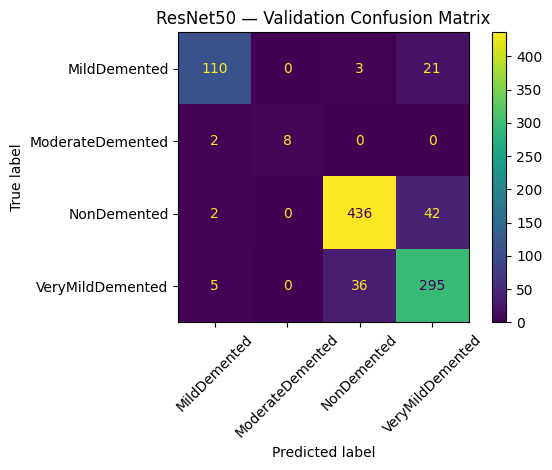


ResNet50 — per-class metrics
                  precision  recall  f1-score   support
MildDemented         0.9244  0.8209    0.8696  134.0000
ModerateDemented     1.0000  0.8000    0.8889   10.0000
NonDemented          0.9179  0.9083    0.9131  480.0000
VeryMildDemented     0.8240  0.8780    0.8501  336.0000
accuracy             0.8844  0.8844    0.8844    0.8844
macro avg            0.9166  0.8518    0.8804  960.0000
weighted avg         0.8868  0.8844    0.8847  960.0000


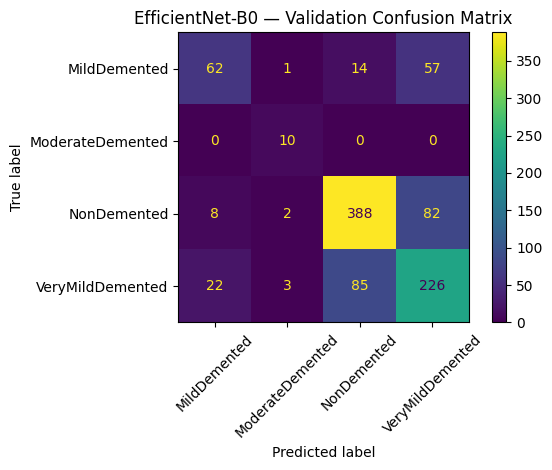


EfficientNet-B0 — per-class metrics
                  precision  recall  f1-score   support
MildDemented         0.6739  0.4627    0.5487  134.0000
ModerateDemented     0.6250  1.0000    0.7692   10.0000
NonDemented          0.7967  0.8083    0.8025  480.0000
VeryMildDemented     0.6192  0.6726    0.6448  336.0000
accuracy             0.7146  0.7146    0.7146    0.7146
macro avg            0.6787  0.7359    0.6913  960.0000
weighted avg         0.7156  0.7146    0.7115  960.0000


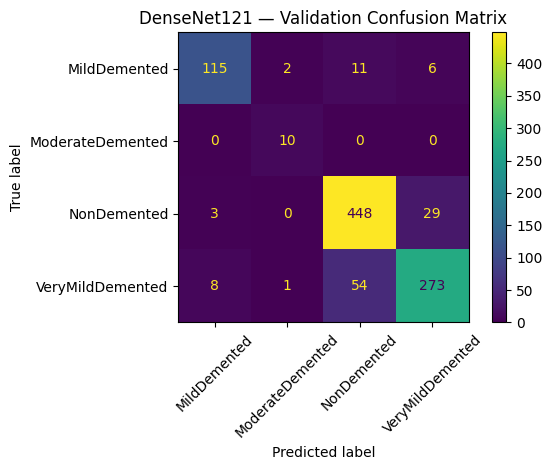


DenseNet121 — per-class metrics
                  precision  recall  f1-score   support
MildDemented         0.9127  0.8582    0.8846  134.0000
ModerateDemented     0.7692  1.0000    0.8696   10.0000
NonDemented          0.8733  0.9333    0.9023  480.0000
VeryMildDemented     0.8864  0.8125    0.8478  336.0000
accuracy             0.8812  0.8812    0.8812    0.8812
macro avg            0.8604  0.9010    0.8761  960.0000
weighted avg         0.8823  0.8812    0.8804  960.0000

VALIDATION COMPARISON
          model  validation_accuracy  validation_macro_f1  validation_weighted_f1  validation_balanced_accuracy  best_validation_loss_during_training
       ResNet50               0.8844               0.8804                  0.8847                        0.8518                                0.3273
    DenseNet121               0.8812               0.8761                  0.8804                        0.9010                                0.3052
EfficientNet-B0               0.7146          

In [27]:

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from torchvision import models
from torch import nn

MODEL_DIR = Path("/content/drive/MyDrive/alzheimer_project/models")
RESULTS_DIR = Path("/content/drive/MyDrive/alzheimer_project/results")

def create_architecture(name, num_classes):
    if name == "ResNet50":
        m = models.resnet50(weights=None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)

    elif name == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(
            m.classifier[1].in_features, num_classes
        )

    elif name == "DenseNet121":
        m = models.densenet121(weights=None)
        m.classifier = nn.Linear(
            m.classifier.in_features, num_classes
        )

    else:
        raise ValueError(name)

    return m.to(device)


model_files = {
    "ResNet50": "resnet50_best.pth",
    "EfficientNet-B0": "efficientnet_b0_best.pth",
    "DenseNet121": "densenet121_best.pth",
}

summary_rows = []
all_reports = {}

for name, filename in model_files.items():
    checkpoint_path = MODEL_DIR / filename
    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    model = create_architecture(name, len(class_names))
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()

    y_true, y_pred, probabilities = [], [], []

    with torch.inference_mode():
        for images, targets in val_loader:
            images = images.to(device)

            logits = model(images)
            probs = torch.softmax(logits, dim=1)

            probabilities.extend(probs.cpu().numpy())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy())
            y_true.extend(targets.numpy())

    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    metrics = {
        "model": name,
        "validation_accuracy": accuracy_score(y_true, y_pred),
        "validation_macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "validation_weighted_f1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "validation_balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "best_validation_loss_during_training":
            checkpoint["best_validation_loss"],
    }

    summary_rows.append(metrics)
    all_reports[name] = {
        "metrics": metrics,
        "classification_report": report,
        "confusion_matrix": confusion_matrix(
            y_true, y_pred, labels=list(range(len(class_names)))
        ).tolist(),
    }

    # Save per-model confusion matrix.
    cm = np.array(all_reports[name]["confusion_matrix"])
    pd.DataFrame(
        cm, index=class_names, columns=class_names
    ).to_csv(
        RESULTS_DIR /
        f"{name.lower().replace('-', '_')}_validation_confusion_matrix.csv"
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    ).plot(xticks_rotation=45, values_format="d")
    plt.title(f"{name} — Validation Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        RESULTS_DIR /
        f"{name.lower().replace('-', '_')}_validation_confusion_matrix.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

    print(f"\n{name} — per-class metrics")
    print(pd.DataFrame(report).T.round(4).to_string())

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

summary_df = pd.DataFrame(summary_rows).sort_values(
    "validation_macro_f1", ascending=False
)

summary_df.to_csv(
    RESULTS_DIR / "validation_model_comparison.csv",
    index=False,
)

with open(RESULTS_DIR / "validation_evaluation_details.json", "w") as f:
    json.dump(all_reports, f, indent=2)

print("\nVALIDATION COMPARISON")
print(summary_df.round(4).to_string(index=False))
print("\nSaved reports and confusion matrices to:", RESULTS_DIR)


In [28]:

from pathlib import Path
import json
import zipfile

PROJECT_DIR = Path("/content/drive/MyDrive/alzheimer_project")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
PACKAGE_DIR = PROJECT_DIR / "portal_package"
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    MODEL_DIR / "resnet50_best.pth",
    MODEL_DIR / "efficientnet_b0_best.pth",
    MODEL_DIR / "densenet121_best.pth",
    RESULTS_DIR / "controlled_experiment_config.json",
    RESULTS_DIR / "validation_model_comparison.csv",
    RESULTS_DIR / "validation_evaluation_details.json",
]

for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Missing artifact: {path}")

# Copy only the required, reproducible artifacts into the package.
for path in required_files:
    destination = PACKAGE_DIR / path.name
    destination.write_bytes(path.read_bytes())

# Add class order and preprocessing details for inference.
portal_config = {
    "class_names": [
        "MildDemented",
        "ModerateDemented",
        "NonDemented",
        "VeryMildDemented",
    ],
    "input_size": 224,
    "input_channels": 3,
    "grayscale_to_rgb": True,
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225],
    },
    "models": {
        "ResNet50": "resnet50_best.pth",
        "EfficientNet-B0": "efficientnet_b0_best.pth",
        "DenseNet121": "densenet121_best.pth",
    },
    "intended_use": (
        "Educational research prototype; not for clinical diagnosis."
    ),
}

with open(PACKAGE_DIR / "portal_config.json", "w") as f:
    json.dump(portal_config, f, indent=2)

zip_path = PROJECT_DIR / "alzheimer_research_portal_artifacts.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in PACKAGE_DIR.iterdir():
        if path.is_file():
            archive.write(path, arcname=path.name)

print("Package created:", zip_path)
print("Package size (MB):", round(zip_path.stat().st_size / 1e6, 2))
print("\nIncluded files:")
for path in sorted(PACKAGE_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size / 1e6:.2f} MB")


Package created: /content/drive/MyDrive/alzheimer_project/alzheimer_research_portal_artifacts.zip
Package size (MB): 129.24

Included files:
controlled_experiment_config.json: 0.00 MB
densenet121_best.pth: 28.44 MB
efficientnet_b0_best.pth: 16.35 MB
portal_config.json: 0.00 MB
resnet50_best.pth: 94.39 MB
validation_evaluation_details.json: 0.01 MB
validation_model_comparison.csv: 0.00 MB
